In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt



In [2]:
df=pd.read_csv('Healthcare_dataset.csv')
df

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results
0,Bobby JacksOn,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.281306,328,Urgent,2024-02-02,Paracetamol,Normal
1,LesLie TErRy,62,Male,A+,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.327287,265,Emergency,2019-08-26,Ibuprofen,Inconclusive
2,DaNnY sMitH,76,Female,A-,Obesity,2022-09-22,Tiffany Mitchell,Cook PLC,Aetna,27955.096079,205,Emergency,2022-10-07,Aspirin,Normal
3,andrEw waTtS,28,Female,O+,Diabetes,2020-11-18,Kevin Wells,"Hernandez Rogers and Vang,",Medicare,37909.782410,450,Elective,2020-12-18,Ibuprofen,Abnormal
4,adrIENNE bEll,43,Female,AB+,Cancer,2022-09-19,Kathleen Hanna,White-White,Aetna,14238.317814,458,Urgent,2022-10-09,Penicillin,Abnormal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
55495,eLIZABeTH jaCkSOn,42,Female,O+,Asthma,2020-08-16,Joshua Jarvis,Jones-Thompson,Blue Cross,2650.714952,417,Elective,2020-09-15,Penicillin,Abnormal
55496,KYle pEREz,61,Female,AB-,Obesity,2020-01-23,Taylor Sullivan,Tucker-Moyer,Cigna,31457.797307,316,Elective,2020-02-01,Aspirin,Normal
55497,HEATher WaNG,38,Female,B+,Hypertension,2020-07-13,Joe Jacobs DVM,"and Mahoney Johnson Vasquez,",UnitedHealthcare,27620.764717,347,Urgent,2020-08-10,Ibuprofen,Abnormal
55498,JENniFER JOneS,43,Male,O-,Arthritis,2019-05-25,Kimberly Curry,"Jackson Todd and Castro,",Medicare,32451.092358,321,Elective,2019-05-31,Ibuprofen,Abnormal


Inspect the data

In [3]:
df.columns


Index(['Name', 'Age', 'Gender', 'Blood Type', 'Medical Condition',
       'Date of Admission', 'Doctor', 'Hospital', 'Insurance Provider',
       'Billing Amount', 'Room Number', 'Admission Type', 'Discharge Date',
       'Medication', 'Test Results'],
      dtype='str')

In [4]:
df.dtypes

Name                      str
Age                     int64
Gender                    str
Blood Type                str
Medical Condition         str
Date of Admission         str
Doctor                    str
Hospital                  str
Insurance Provider        str
Billing Amount        float64
Room Number             int64
Admission Type            str
Discharge Date            str
Medication                str
Test Results              str
dtype: object

In [5]:
df.isnull().sum()

Name                  0
Age                   0
Gender                0
Blood Type            0
Medical Condition     0
Date of Admission     0
Doctor                0
Hospital              0
Insurance Provider    0
Billing Amount        0
Room Number           0
Admission Type        0
Discharge Date        0
Medication            0
Test Results          0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(534)

In [7]:
df.describe()#statistical summary

,Age,Billing Amount,Room Number
count,55500.000000,55500.000000,55500.000000
mean,51.539459,25539.316097,301.134829
std,19.602454,14211.454431,115.243069
min,13.000000,-2008.492140,101.000000
25%,35.000000,13241.224652,202.000000
50%,52.000000,25538.069376,302.000000
75%,68.000000,37820.508436,401.000000
max,89.000000,52764.276736,500.000000


Data Cleaning

In [8]:
df=df.drop_duplicates()

In [9]:
df.duplicated().sum()

np.int64(0)

Cleaning Name Columns

In [10]:
df['Name']=df['Name'].str.strip().str.title()

In [11]:
df.head()

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results
0,Bobby Jackson,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.281306,328,Urgent,2024-02-02,Paracetamol,Normal
1,Leslie Terry,62,Male,A+,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.327287,265,Emergency,2019-08-26,Ibuprofen,Inconclusive
2,Danny Smith,76,Female,A-,Obesity,2022-09-22,Tiffany Mitchell,Cook PLC,Aetna,27955.096079,205,Emergency,2022-10-07,Aspirin,Normal
3,Andrew Watts,28,Female,O+,Diabetes,2020-11-18,Kevin Wells,"Hernandez Rogers and Vang,",Medicare,37909.782410,450,Elective,2020-12-18,Ibuprofen,Abnormal
4,Adrienne Bell,43,Female,AB+,Cancer,2022-09-19,Kathleen Hanna,White-White,Aetna,14238.317814,458,Urgent,2022-10-09,Penicillin,Abnormal


fix Negative Billing Amount

In [12]:
df.loc[df['Billing Amount']<0,'Billing Amount']=df['Billing Amount'].mean()

In [13]:
df.describe()

,Age,Billing Amount,Room Number
count,54966.000000,54966.000000,54966.000000
mean,51.535185,25594.536582,301.124404
std,19.605661,14162.191537,115.223143
min,13.000000,9.238787,101.000000
25%,35.000000,13326.001350,202.000000
50%,52.000000,25544.306284,302.000000
75%,68.000000,37819.858159,401.000000
max,89.000000,52764.276736,500.000000


In [14]:
df['Date of Admission']=pd.to_datetime(df['Date of Admission'])
df['Discharge Date']=pd.to_datetime(df['Discharge Date'])

In [15]:
df.dtypes

Name                             str
Age                            int64
Gender                           str
Blood Type                       str
Medical Condition                str
Date of Admission     datetime64[us]
Doctor                           str
Hospital                         str
Insurance Provider               str
Billing Amount               float64
Room Number                    int64
Admission Type                   str
Discharge Date        datetime64[us]
Medication                       str
Test Results                     str
dtype: object

In [16]:
df['Length_of_stay']=(df['Discharge Date']-df['Date of Admission']).dt.days

In [17]:
df.head()

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results,Length_of_stay
0,Bobby Jackson,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.281306,328,Urgent,2024-02-02,Paracetamol,Normal,2
1,Leslie Terry,62,Male,A+,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.327287,265,Emergency,2019-08-26,Ibuprofen,Inconclusive,6
2,Danny Smith,76,Female,A-,Obesity,2022-09-22,Tiffany Mitchell,Cook PLC,Aetna,27955.096079,205,Emergency,2022-10-07,Aspirin,Normal,15
3,Andrew Watts,28,Female,O+,Diabetes,2020-11-18,Kevin Wells,"Hernandez Rogers and Vang,",Medicare,37909.782410,450,Elective,2020-12-18,Ibuprofen,Abnormal,30
4,Adrienne Bell,43,Female,AB+,Cancer,2022-09-19,Kathleen Hanna,White-White,Aetna,14238.317814,458,Urgent,2022-10-09,Penicillin,Abnormal,20


final cleaning check

In [18]:
df.isnull().sum()

Name                  0
Age                   0
Gender                0
Blood Type            0
Medical Condition     0
Date of Admission     0
Doctor                0
Hospital              0
Insurance Provider    0
Billing Amount        0
Room Number           0
Admission Type        0
Discharge Date        0
Medication            0
Test Results          0
Length_of_stay        0
dtype: int64

In [19]:
df.shape

(54966, 16)

Data Analysis and Data Visualization

1. which medical condition  affects the most patients across the network

In [20]:
condition_counts=df['Medical Condition'].value_counts()
condition_counts

Medical Condition
Arthritis       9218
Diabetes        9216
Hypertension    9151
Obesity         9146
Cancer          9140
Asthma          9095
Name: count, dtype: int64

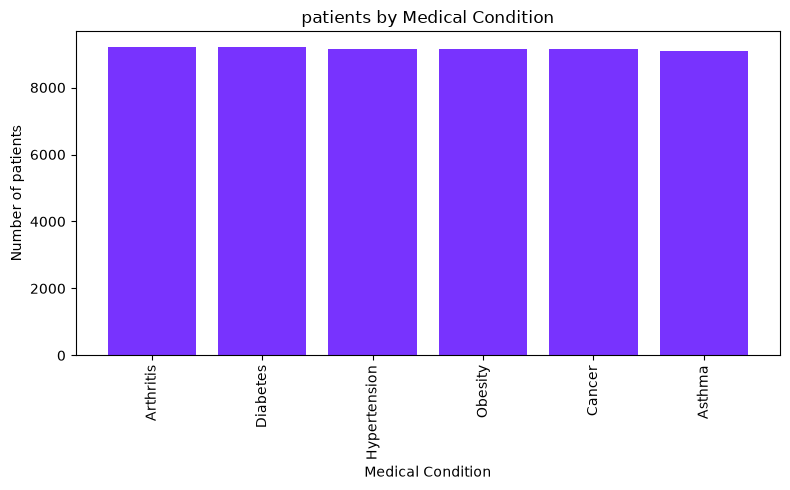

In [21]:
plt.figure(figsize=(8,5))
plt.bar(condition_counts.index,condition_counts.values,color='#7833FE')
plt.title('patients by Medical Condition')
plt.xlabel('Medical Condition')
plt.ylabel('Number of patients')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()



2. How is patient age distributed across the network?

In [22]:
average_age=df['Age'].mean()
average_age

np.float64(51.53518538733035)

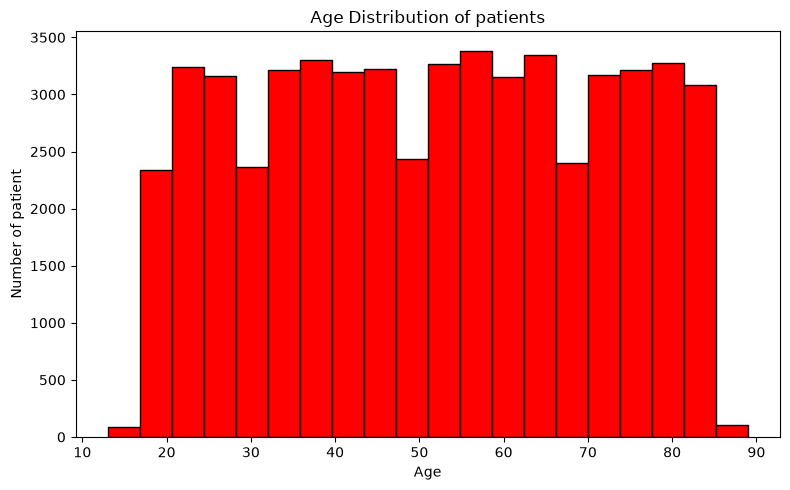

In [23]:
plt.figure(figsize=(8,5))
plt.hist(df['Age'],bins=20,color='red',edgecolor='black')
plt.title('Age Distribution of patients')
plt.xlabel('Age')
plt.ylabel('Number of patient')
plt.tight_layout()
plt.show()

3.how has average treatment cost changed over time?

In [24]:
average_cost=df['Billing Amount'].mean()
average_cost

np.float64(25594.536582219524)

In [25]:
df['Admission_month']=df['Date of Admission'].dt.to_period('M')
monthly_avg_cost=df.groupby('Admission_month')['Billing Amount'].mean()
monthly_avg_cost

Admission_month
2019-05    25897.449655
2019-06    26324.004064
2019-07    25928.602371
2019-08    25457.102225
2019-09    24915.548929
               ...     
2024-01    25836.695757
2024-02    25703.588425
2024-03    25310.583403
2024-04    24930.033214
2024-05    25464.902913
Freq: M, Name: Billing Amount, Length: 61, dtype: float64

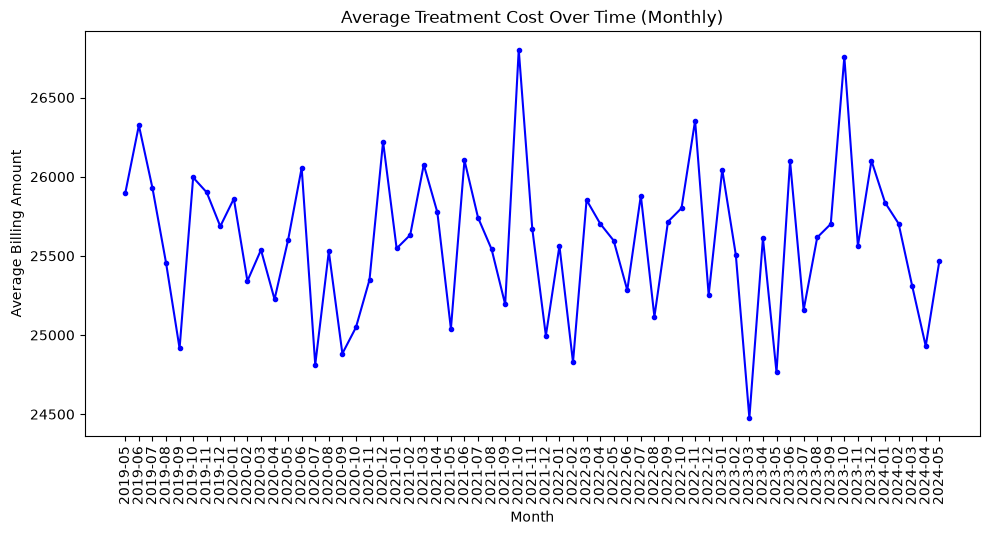

In [26]:
plt.figure(figsize=(10,5))
plt.plot(monthly_avg_cost.index.astype(str),monthly_avg_cost.values,color='blue',marker='o',markersize='3')
plt.title("Average Treatment Cost Over Time (Monthly)")
plt.xlabel('Month')
plt.ylabel('Average Billing Amount')
plt.tight_layout()
plt.xticks(rotation=90)
plt.show()

4 is there a relationship between patient age and treatment cost?

In [29]:
senior_avg_cost=df.loc[df['Age']>=60,'Billing Amount'].mean()
senior_avg_cost

np.float64(25563.58776383007)

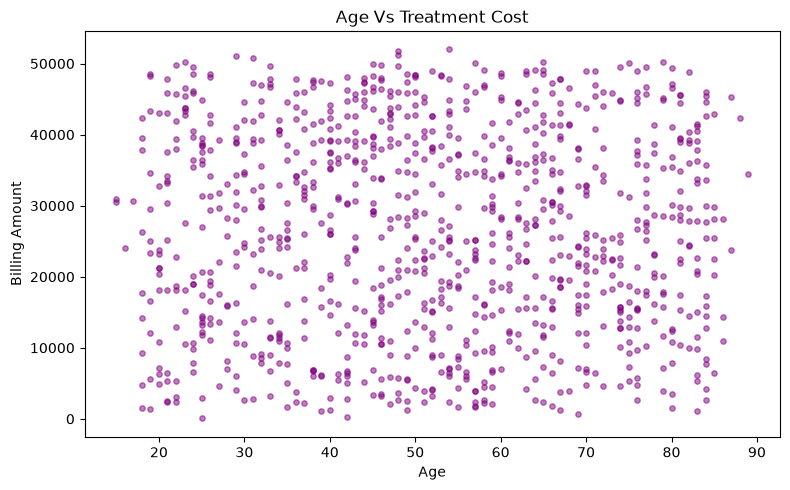

In [30]:
sample_df=df.sample(1000,random_state=1)
plt.figure(figsize=(8,5))
plt.scatter(sample_df['Age'],sample_df['Billing Amount'],color='purple',alpha=0.5,s=15)
plt.title('Age Vs Treatment Cost')
plt.xlabel ('Age')
plt.ylabel('Billing Amount')
plt.tight_layout()
plt.show()

5.which insurance providers covers the most patients ?

In [31]:
Insurance_count=df['Insurance Provider'].value_counts()
Insurance_count

Insurance Provider
Cigna               11139
Medicare            11039
UnitedHealthcare    11014
Blue Cross          10952
Aetna               10822
Name: count, dtype: int64

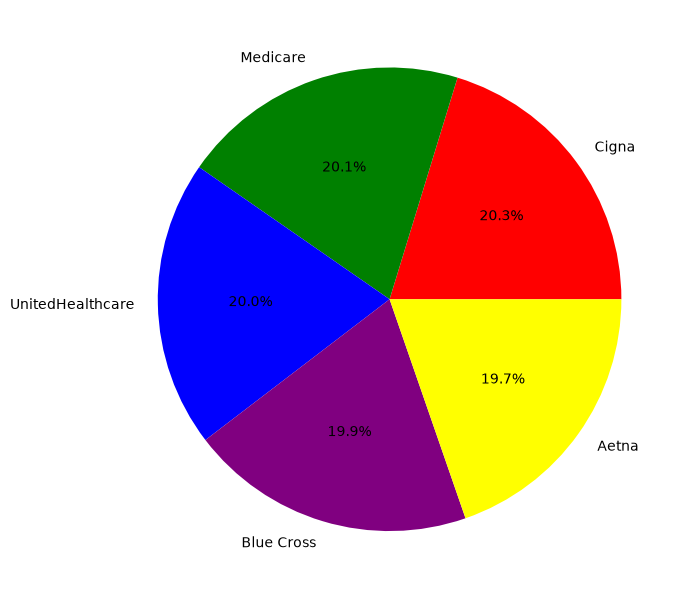

In [32]:
plt.figure(figsize =(7,7))
plt.pie(Insurance_count.values,labels=Insurance_count.index,autopct='%1.1f%%',colors=['Red','Green','Blue','Purple','yellow'])
plt.title=('Patient Share by Insurance Provider')
plt.tight_layout()
plt.show()

Ad-Hoc Business Questions
1. Emergency department Capacity planning
Business Scenario: the hospital management is planning staffing for emergency cases.They want to know how many emergency admission  occured in each month.

In [34]:
df.dtypes

Name                             str
Age                            int64
Gender                           str
Blood Type                       str
Medical Condition                str
Date of Admission     datetime64[us]
Doctor                           str
Hospital                         str
Insurance Provider               str
Billing Amount               float64
Room Number                    int64
Admission Type                   str
Discharge Date        datetime64[us]
Medication                       str
Test Results                     str
Length_of_stay                 int64
Admission_month            period[M]
dtype: object

In [35]:
emergency_month=(df.loc[df['Admission Type']=='Emergency'].groupby(df['Date of Admission'].dt.month).size())
emergency_month

Date of Admission
1     1547
2     1452
3     1528
4     1473
5     1533
6     1483
7     1573
8     1533
9     1500
10    1490
11    1462
12    1528
dtype: int64

q
AD-Hoc Question-2 identify High-Cost Patient Groups
Business Scenario: Hospital finance team wants to identify patients who have unusually  high billing amount sp they can review those cases.

In [37]:
high_cost_patients=df.loc[df['Billing Amount']>df['Billing Amount'].quantile(0.90)]
high_cost_patients.shape[0]


5497

AD-Hoc question-3 Flagging Emergency Cases with Abnormal Results  for review
Busines scenario: Hospital management want to identify emergency patients whose test result are abnormal ,so these cases can be priotized for  review.

In [39]:
priority_cases =df.loc[(df['Admission Type']=='Emergency') & (df['Test Results']=='Abnormal')]
priority_cases

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results,Length_of_stay,Admission_month
12,Connor Hansen,75,Female,A+,Diabetes,2019-12-12,Kenneth Fletcher,"Powers Miller, and Flores",Cigna,43282.283358,134,Emergency,2019-12-28,Penicillin,Abnormal,16,2019-12
27,Mr. Kenneth Moore,34,Female,A+,Diabetes,2022-06-21,James Ellis,Serrano-Dixon,UnitedHealthcare,18834.801341,157,Emergency,2022-06-30,Lipitor,Abnormal,9,2022-06
38,Nicole Lucero,70,Female,O-,Diabetes,2022-03-12,Christine Johnson,"and Garcia Morris Cunningham,",Cigna,48290.693407,113,Emergency,2022-03-29,Lipitor,Abnormal,17,2022-03
51,Stephanie Kent,42,Female,A-,Cancer,2019-06-15,Mary Moss,Beck-Galloway,Aetna,14681.016360,234,Emergency,2019-07-05,Ibuprofen,Abnormal,20,2019-06
64,Nancy Glover,58,Male,A-,Hypertension,2020-05-08,Jennifer Larson,"Khan, and Rodriguez Fischer",Medicare,19183.168885,378,Emergency,2020-06-01,Aspirin,Abnormal,24,2020-05
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
55471,Ian Murphy,73,Female,B+,Hypertension,2023-05-03,Leslie Guerra,Lozano Ltd,Aetna,28397.377193,348,Emergency,2023-05-06,Lipitor,Abnormal,3,2023-05
55480,Lauren Mills,33,Female,B-,Diabetes,2020-09-30,Mr. David Murray MD,"Riggs, King and Walls",Cigna,22375.523434,323,Emergency,2020-10-26,Aspirin,Abnormal,26,2020-09
55488,Brittney York,43,Female,B-,Obesity,2024-02-02,Richard Matthews,Malone Ltd,Blue Cross,8128.932064,469,Emergency,2024-02-04,Aspirin,Abnormal,2,2024-02
55490,Stephanie Oliver,82,Male,B-,Cancer,2022-01-10,Gary Leblanc,Group Lee,Cigna,17350.543524,381,Emergency,2022-01-21,Penicillin,Abnormal,11,2022-01
